# Single Reservoir

In [1]:
from dataclasses import dataclass 
import numpy as np
import matplotlib.pyplot as plt

| **Parameter**          | **Description**             | **Units** | **Constraints**                                | **Role in the Model**                                                                        |
| ---------------------- | --------------------------- | --------- | ---------------------------------------------- | -------------------------------------------------------------------------------------------- |
| **`A`**                | Catchment Area              | $m^2$     | $> 0$                                          | Scales the total precipitation collected by the surrounding basin.                           |
| **`B`**                | Seepage Coefficient         | $m/s$     | $\ge 0$                                        | Determines how much water leaks into the groundwater/soil.                                   |
| **`P`**                | Precipitation Rate          | $m/s$     | $\ge 0$                                        | The baseline average rainfall driving water into the system.                                 |
| **`E`**                | Evaporation Rate            | $m/s$     | $\ge 0$ (usually $< P$)                        | The baseline rate at which surface water evaporates into the atmosphere.                     |
| **`Phi` ($\Phi$)**     | Runoff / Pumped Fraction    | None      | $0 \le \Phi \le 1$                             | The percentage of precipitation diverted, pumped, or lost before it can enter the reservoir. |
| **`alpha` ($\alpha$)** | Scaling Exponent (Inflow)   | None      | $> 0$                                           | Relates the physical water volume to the effective surface area receiving rainfall.          |
| **`beta` ($\beta$)**   | Scaling Exponent (Outflow)  | None      | $> 0$                                          | Relates water volume to the discharge rate (e.g., how fast water leaves the spillway).       |
| **`gamma` ($\gamma$)** | Scaling Exponent (Seepage)  | None      | $> 0$                                          | Relates water volume to groundwater seepage rates based on lakebed pressure/geometry.        |
| **`sigma_1`**          | Precipitation Noise         | None      | $> 0$                                          | The volatility/intensity of random fluctuations in rainfall.                                 |
| **`sigma_2`**          | Evaporation Noise           | None      | $> 0$                                          | The volatility of random fluctuations in evaporation (due to wind/temperature).              |
| **`sigma_3`**          | Catchment Noise             | None      | $> 0$                                          | The volatility of random fluctuations in the basin runoff or pumping efficiency.             |
| **`c`, `e`**           | $\psi(X)$ Scaling Constants | Varies    | Case dependent                                 | Modifiers used to define the lake's surface-area-to-volume ratio in Case III.                |
| **`a_p`, `b_p`**       | $\psi(X)$ Geometric Bounds  | None      | Case dependent                                 | Defines the extreme boundaries of the surface area ratio in the mathematical proofs.         |
| **`n`**                | $\psi(X)$ Polynomial Degree | None      | Integer $\ge 1$                                | Dictates whether the lake's banks slope linearly ($n=1$), quadratically ($n=2$), etc.        |


In [ ]:
@dataclass
class Hydrology:
    A: float  = 1 # Area of the catchment (m^2)
    B: float  = 0 # Seepage coefficient (m/s)

    P: float  = 1 # Precipitation rate (m/s)
    E: float  = 0.1 # Evaporation rate (m/s)
    Phi: float  = 0.7 # Percentage pumped out

    alpha: float  = 1 # Shape scaling exponent
    beta: float  = 1 # Shape scaling exponent
    gamma: float  = 1 # Shape scaling exponent

    sigma_1: float  = 0.1 # Standard deviation of the first noise term
    sigma_2: float  = 0.1 # Standard deviation of the second noise term
    sigma_3: float  = 0.1 # Standard deviation of the third noise term

    # For Psi
    c: float  = 0 # Constant in Psi
    e: float  = 0.1 # Constant in Psi
    a_p: float  = 1 # Constant in Psi
    b_p: float  = 1 # Constant in Psi
    n: float  = 1 # Constant in Psi

$$\psi(X) = c + e\left(\frac{X}{a_p}\right)^{\frac{n}{b_p}}$$

In [3]:
def psi(X, p: Hydrology):
    """
    This represents the ratio of the surface area of the surrounding land (catchment) to the surface 
    area of the reservoir itself.
    """
    return (p.c + p.e * (X / p.a_p) ** (p.n / p.b_p))

$$\psi'(X) = \frac{n \cdot e}{b_p \cdot a_p^{n/b_p}} X^{\frac{n-b_p}{b_p}}$$

In [ ]:
def psi_prime(X, p: Hydrology):
    """
    This represents the derivative of the ratio of the surface area of the surrounding land (catchment) to the surface area of the reservoir itself with respect to X. 
    """
    return (p.e * (p.n / p.b_p) * (1 / p.a_p) ** (p.n / p.b_p) * X ** ((p.n / p.b_p) - 1))

$$F(x) = A x^\alpha \Big[ P(1 - \Phi) + \psi(x)(P\Phi - E) \Big] - Ax^\beta - Bx^\gamma$$
$$F_1 = P(1 - \Phi) + \psi(X)(P\Phi - E)$$

$$F_2 = -A X^\beta - B X^\gamma$$

$$F(X) = A X^\alpha F_1 + F_2$$

In [ ]:
def F(X, p: Hydrology):
    """
    This function calculates the deterministic part of the reservoir level change, considering precipitation, evaporation, and seepage. 
    """
    psi_x = psi(X, p)
    F1 = p.P * (1 - p.Phi) + psi_x * (p.P * p.Phi - p.E)
    F2 = -p.A * X**p.beta - p.B * X**p.gamma
    return (p.A*X**p.alpha * F1 + F2)

The Diffusion Terms:
1. $$g_1(X) = A \sigma_1 X^\alpha (1 - \Phi + \Phi\psi(X))$$
2. $$g_2(X) = -A \sigma_2 X^\alpha \psi(X)$$
3. $$g_3(X) = -A \sigma_3 P X^\alpha (1 - \psi(X))$$

In [ ]:
def Calculate_g(X, p: Hydrology):
    """
    This function calculates the stochastic part of the reservoir level change, considering three independent noise terms.
    """
    psi_x = psi(X, p)
    g1 = p.A * p.sigma_1 * X**p.alpha * (1 - p.Phi + psi_x * p.Phi)
    g2 = - p.A * p.sigma_2 * X**p.alpha * psi_x
    g3 = - p.A * p.sigma_3 *p.P * X**p.alpha * (1 - psi_x) 
    return [g1, g2, g3]

The Derivatives:
1. $$g_1'(X) = A \sigma_1 \left[ \alpha X^{\alpha-1} (1 - \Phi + \Phi\psi(X)) + X^\alpha \Phi \psi'(X) \right]$$
2. $$g_2'(X) = -A \sigma_2 \left[ \alpha X^{\alpha-1} \psi(X) + X^\alpha \psi'(X) \right]$$
3. $$g_3'(X) = -A \sigma_3 P \left[ \alpha X^{\alpha-1} (1 - \psi(X)) - X^\alpha \psi'(X) \right]$$

In [ ]:
def Calculate_g_prime(X, p: Hydrology):
    """
    This function calculates the derivatives of the stochastic part of the reservoir level change with respect to X, considering three independent noise terms. 
    """
    psi_x = psi(X, p)
    psi_prime_x = psi_prime(X, p)
    g1_prime = p.A * p.sigma_1 * (p.alpha * X**(p.alpha - 1) * (1 - p.Phi + psi_x * p.Phi) + X**p.alpha * psi_prime_x * p.Phi)
    g2_prime = - p.A * p.sigma_2 * (p.alpha * X**(p.alpha - 1) * psi_x + X**p.alpha * psi_prime_x)
    g3_prime = - p.A * p.sigma_3 * p.P * ((p.alpha * X**(p.alpha - 1) * (1 - psi_x) - X**p.alpha * psi_prime_x))
    return [g1_prime, g2_prime, g3_prime]

In standard ODEs, the drift is just $F(X)$. But because we are converting a Stratonovich SDE to an Itô SDE for our numerical solver, we have to add the noise-induced drift correction (also called the Stratonovich correction).The formula for the total Itô drift is:
$$\text{Drift}(X) = F(X) + \frac{1}{2} \sum_{i=1}^{3} g_i(X)g_i'(X)$$

In [ ]:
def Drift(X, p: Hydrology):
    """
    This function calculates the drift term of the stochastic differential equation, which is the sum of the deterministic part and a correction term that accounts for the stochastic part. 
    """
    g_vals = Calculate_g(X, p)
    g_prime_vals = Calculate_g_prime(X, p)
    corrected_term = (1/2) * sum(g_val * g_prime_val for g_val, g_prime_val in zip(g_vals, g_prime_vals))
    return F(X, p) + corrected_term

**Updation Rule for Euler Maruyama**

$$X_{next} = X_{prev} + \text{Drift}(X_{prev}) \cdot dt + g_1(X_{prev})dW_1 + g_2(X_{prev})dW_2 + g_3(X_{prev})dW_3$$

In [ ]:
def EulerMaruyama(X0, p: Hydrology, T, N, M):
    """
    This function implements the Euler-Maruyama method to simulate the stochastic differential equation governing the reservoir level. 
    """
    dt = T / N
    X = np.zeros((N, M))
    X[0, :] = X0
    sqrt_dt = np.sqrt(dt)
    floor_val = 1e-8

    for i in range(1, N):
        X_prev = X[i - 1, :]

        # Noise terms for the three independent Brownian motions
        dW1, dW2, dW3 = np.random.normal(loc=0.0, scale=sqrt_dt, size=(3, M))

        # Drift and diffusion terms
        drift = Drift(X_prev, p)
        g_vals = Calculate_g(X_prev, p)

        # Updation step From Euler-Maruyama method
        X[i, :] = X_prev + drift * dt + g_vals[0] * dW1 + g_vals[1] * dW2 + g_vals[2] * dW3
        X[i, :] = np.maximum(X[i, :], floor_val)

    return X

In [19]:
def plot_simulation(X, T, N):
    time = np.linspace(0, T, N)

    plt.plot(time, X[:,:10], color = 'grey', alpha=0.5)  # Plotting first 10 sample paths
    mean_path = np.mean(X, axis=1)
    plt.plot(time, mean_path, color='blue', label='Mean Path', linewidth=2)

    plt.title('Euler-Maruyama Simulation of Stochastic Hydrology Model')
    plt.xlabel('Time')
    plt.ylabel('Reservoir Level (X)')
    plt.legend()
    plt.grid()
    plt.show()

In [20]:
P = Hydrology()
T = 10
N = 1000  # Number of time steps
M = 100  # Number of sample paths
X0 = 0.5  # Initial reservoir level

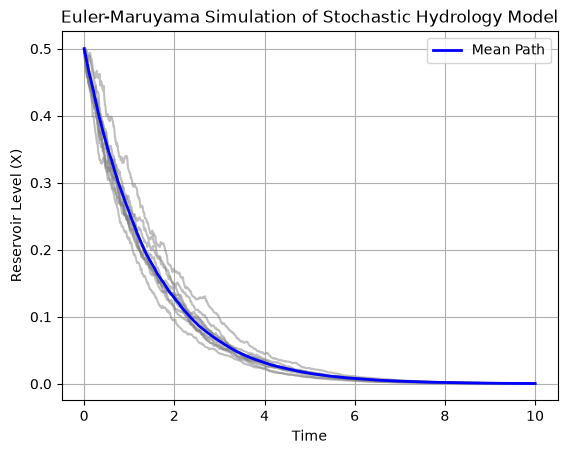

In [21]:
X_paths = EulerMaruyama(X0, P, T, N, M)
plot_simulation(X_paths, T, N)